Load the data

In [13]:
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
ds = load_dataset("maharshipandya/spotify-tracks-dataset", split="train")
df = ds.to_pandas()
df.to_parquet("../data/spotify_tracks_raw.parquet")

print(df.shape)
df.info()

(114000, 21)
<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          

First checks

In [14]:
print(df["popularity"].describe().round(1))
print("Share of tracks with popularity 0:", round((df["popularity"] == 0).mean(), 3))
print("Unique track_id:", df["track_id"].nunique(), "of", len(df))
print("Genres:", df["track_genre"].nunique())
print("Missing values:")
print(df.isna().sum()[lambda s: s > 0])
df.head(3)

count    114000.0
mean         33.2
std          22.3
min           0.0
25%          17.0
50%          35.0
75%          50.0
max         100.0
Name: popularity, dtype: float64
Share of tracks with popularity 0: 0.141
Unique track_id: 89741 of 114000
Genres: 114
Missing values:
artists       1
album_name    1
track_name    1
dtype: int64


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.461,...,-6.746,0,0.1430,0.0322,0.000001,0.358,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.166,...,-17.235,1,0.0763,0.9240,0.000006,0.101,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.359,...,-9.734,1,0.0557,0.2100,0.000000,0.117,0.120,76.332,4,acoustic


Cleaning

In [15]:
df = df.drop(columns=["Unnamed: 0"])
print(df[df["artists"].isna()][["track_id", "track_name", "artists", "track_genre"]])
df = df.dropna(subset=["artists", "album_name", "track_name"])

feat = ["duration_ms", "danceability", "energy", "loudness", "speechiness",
        "acousticness", "instrumentalness", "liveness", "valence", "tempo"]

dup = df[df.duplicated("track_id", keep=False)]
print("Rows sharing a track_id:", len(dup), "| distinct ids:", dup["track_id"].nunique())
print("Share of repeated ids with identical popularity:",
      round(dup.groupby("track_id")["popularity"].nunique().eq(1).mean(), 3))
print("Share of repeated ids with identical audio features:",
      round(dup.groupby("track_id")[feat].nunique().eq(1).all(axis=1).mean(), 3))
print("Same artist + title under different track_ids:",
      df.drop_duplicates("track_id").duplicated(["artists", "track_name"]).sum())
print(df.groupby("track_id")["track_genre"].nunique().describe().round(2))

                     track_id track_name artists track_genre
65900  1kR4gIb7nGxHPI3D2ifs59        NaN     NaN       k-pop
Rows sharing a track_id: 40900 | distinct ids: 16641
Share of repeated ids with identical popularity: 0.957
Share of repeated ids with identical audio features: 1.0
Same artist + title under different track_ids: 8397
count    89740.00
mean         1.27
std          0.66
min          1.00
25%          1.00
50%          1.00
75%          1.00
max          9.00
Name: track_genre, dtype: float64


In [16]:
spread = df.groupby("track_id")["popularity"].agg(lambda s: s.max() - s.min())
print("Largest popularity gap within a track_id:", spread.max())

agg = {c: "first" for c in df.columns if c not in ("track_id", "track_genre", "popularity")}
agg["popularity"] = "mean"
tracks = df.groupby("track_id", as_index=False).agg(agg)

genres = df.groupby("track_id")["track_genre"].agg(list)
tracks["genres"] = tracks["track_id"].map(genres)
tracks["n_genres"] = tracks["genres"].str.len()
print(tracks.shape, tracks["n_genres"].describe().round(2).to_dict())
tracks.to_parquet("../data/tracks.parquet")

Largest popularity gap within a track_id: 44
(89740, 21) {'count': 89740.0, 'mean': 1.27, 'std': 0.67, 'min': 1.0, '25%': 1.0, '50%': 1.0, '75%': 1.0, 'max': 9.0}


             zero_share  median     n
track_genre                          
jazz               0.68     0.0  1000
iranian            0.66     0.0  1000
romance            0.64     0.0  1000
soul               0.61     0.0  1000
latin              0.59     0.0  1000
country            0.59     0.0  1000
rock               0.52     0.0  1000
dance              0.49     1.0  1000
alternative        0.48     1.0  1000
house              0.40    41.5  1000
count    114.00
mean       0.14
std        0.17
min        0.00
25%        0.02
50%        0.07
75%        0.20
max        0.68
Name: zero_share, dtype: float64
is_zero                False       True 
duration_ms       215360.000  197680.000
danceability           0.576       0.577
energy                 0.683       0.615
loudness              -7.193      -7.076
speechiness            0.049       0.047
acousticness           0.181       0.253
instrumentalness       0.000       0.000
liveness               0.133       0.125
valence       

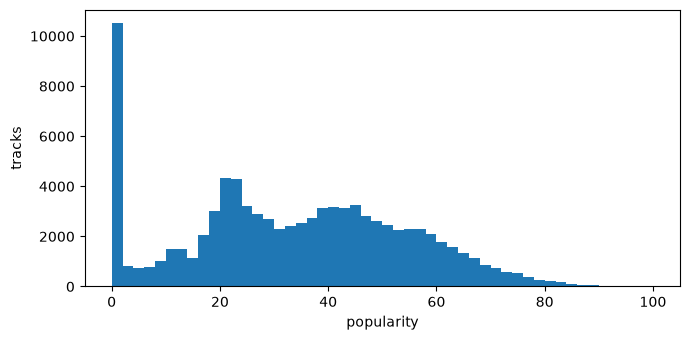

In [17]:
by_genre = df.groupby("track_genre")["popularity"].agg(
    zero_share=lambda s: (s == 0).mean(), median="median", n="size")
print(by_genre.sort_values("zero_share", ascending=False).head(10).round(2))
print(by_genre["zero_share"].describe().round(2))

print(tracks.assign(is_zero=tracks["popularity"] == 0)
            .groupby("is_zero")[feat].median().round(3).T)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(tracks["popularity"], bins=50)
ax.set_xlabel("popularity"); ax.set_ylabel("tracks")
plt.tight_layout()
plt.savefig("../images/popularity_hist.png", dpi=150, bbox_inches="tight")
plt.show()

Features for splitting, then the first EDA

In [18]:
import re
import numpy as np

tracks = pd.read_parquet("../data/tracks.parquet")

def norm(s):
    return re.sub(r"\s+", " ", str(s).lower()).strip()

tracks["song_key"] = tracks["artists"].map(norm) + " || " + tracks["track_name"].map(norm)
tracks["first_artist"] = tracks["artists"].str.split(";").str[0].map(norm)
tracks["n_artists"] = tracks["artists"].str.count(";") + 1
tracks["is_zero"] = tracks["popularity"] == 0
tracks["duration_min"] = tracks["duration_ms"] / 60000

print("Distinct songs (artist + title):", tracks["song_key"].nunique(), "of", len(tracks))
print("Distinct lead artists:", tracks["first_artist"].nunique())
print("Zero share, one row per track:", round(tracks["is_zero"].mean(), 3))
tracks.to_parquet("../data/tracks.parquet")

Distinct songs (artist + title): 81206 of 89740
Distinct lead artists: 17639
Zero share, one row per track: 0.104


subset            all tracks  non-zero only
feature                                    
instrumentalness      -0.124         -0.197
speechiness           -0.067         -0.099
energy                -0.016         -0.068
liveness              -0.012         -0.037
duration_min           0.013         -0.034
tempo                  0.008         -0.019
valence               -0.011         -0.002
acousticness           0.010          0.060
n_artists              0.033          0.064
danceability           0.055          0.064
loudness               0.067          0.078


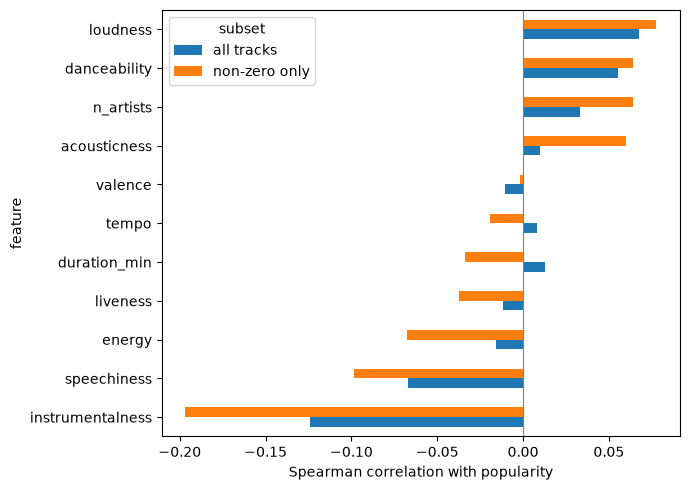

In [19]:
from scipy.stats import spearmanr

num_feats = ["danceability", "energy", "loudness", "speechiness", "acousticness",
             "instrumentalness", "liveness", "valence", "tempo", "duration_min", "n_artists"]
rows = []
for name, sub in [("all tracks", tracks), ("non-zero only", tracks[~tracks["is_zero"]])]:
    for f in num_feats:
        rho, _ = spearmanr(sub[f], sub["popularity"])
        rows.append({"subset": name, "feature": f, "rho": rho})

corr = (pd.DataFrame(rows).pivot(index="feature", columns="subset", values="rho")
          .sort_values("non-zero only"))
print(corr.round(3))

corr.plot.barh(figsize=(7, 5))
plt.axvline(0, color="gray", lw=0.8)
plt.xlabel("Spearman correlation with popularity")
plt.tight_layout()
plt.savefig("../images/correlations.png", dpi=150, bbox_inches="tight")
plt.show()

          median  mean   size
explicit                     
False       37.0  36.7  73455
True        41.0  41.0   6938 

      median  mean   size
mode                     
0       37.0  37.2  29425
1       37.0  37.0  50968 

                median  mean   size
time_signature                     
0                 35.5  37.9    158
1                 28.0  32.3    737
3                 32.0  34.5   6517
4                 37.0  37.4  71615
5                 30.0  33.4   1366 

     median  mean  size
key                    
0      37.0  37.0  9147
1      36.0  36.7  7673
2      37.0  37.0  8488
3      38.0  37.9  2429
4      37.0  37.2  6527
5      37.0  37.4  6442
6      37.0  37.4  5491
7      36.0  36.2  9508
8      38.0  38.2  4925
9      36.0  36.6  8072
10     37.0  36.8  5261
11     38.0  37.6  6430 



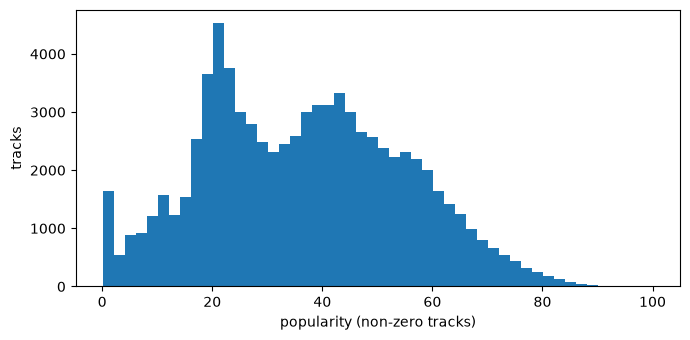

In [20]:
nz = tracks[~tracks["is_zero"]]
for c in ["explicit", "mode", "time_signature", "key"]:
    print(nz.groupby(c)["popularity"].agg(["median", "mean", "size"]).round(1), "\n")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(nz["popularity"], bins=50)
ax.set_xlabel("popularity (non-zero tracks)"); ax.set_ylabel("tracks")
plt.tight_layout()
plt.savefig("../images/popularity_hist_nonzero.png", dpi=150, bbox_inches="tight")
plt.show()

How much can the audio features predict?

In [21]:
import warnings
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from lightgbm import LGBMRegressor

nz = tracks[~tracks["is_zero"]].reset_index(drop=True).copy()
nz["explicit"] = nz["explicit"].astype(int)

num_cols = ["danceability", "energy", "loudness", "speechiness", "acousticness",
            "instrumentalness", "liveness", "valence", "tempo", "duration_min", "n_artists"]
X = nz[num_cols + ["explicit", "mode", "key", "time_signature"]]
y = nz["popularity"]

prep = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["key", "time_signature"]),
    ("bin", "passthrough", ["explicit", "mode"]),
])

def make(m):
    return Pipeline([("prep", prep), ("m", m)])

models = {
    "Mean baseline": make(DummyRegressor()),
    "Ridge": make(Ridge(alpha=1.0)),
    "LightGBM": make(LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=31,
                                   min_child_samples=50, subsample=0.8, subsample_freq=1,
                                   colsample_bytree=0.8, random_state=42, verbose=-1)),
}

def cv_eval(model, X, y, groups, n_splits=5):
    rows = []
    for tr, te in GroupKFold(n_splits=n_splits).split(X, y, groups):
        model.fit(X.iloc[tr], y.iloc[tr])
        p = model.predict(X.iloc[te])
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            rho = spearmanr(y.iloc[te], p)[0]
        rows.append({"R2": r2_score(y.iloc[te], p),
                     "MAE": mean_absolute_error(y.iloc[te], p),
                     "Spearman": rho})
    return pd.DataFrame(rows)

schemes = {"by song": nz["song_key"], "by lead artist": nz["first_artist"]}
out = []
for sname, groups in schemes.items():
    for mname, model in models.items():
        r = cv_eval(model, X, y, groups)
        out.append({"split": sname, "model": mname,
                    "R2": f"{r['R2'].mean():.3f} ± {r['R2'].std():.3f}",
                    "MAE": f"{r['MAE'].mean():.2f}",
                    "Spearman": f"{r['Spearman'].mean():.3f}"})
results = pd.DataFrame(out)
print(results.to_string(index=False))
results.to_csv("../results/model_comparison_audio_only.csv", index=False)

         split         model             R2   MAE Spearman
       by song Mean baseline -0.000 ± 0.000 15.15      nan
       by song         Ridge  0.075 ± 0.001 14.33    0.268
       by song      LightGBM  0.184 ± 0.001 13.07    0.426
by lead artist Mean baseline -0.004 ± 0.004 15.16      nan
by lead artist         Ridge  0.069 ± 0.018 14.37    0.263
by lead artist      LightGBM  0.165 ± 0.018 13.24    0.407


How much of this is genre?

In [22]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()
G = pd.DataFrame(mlb.fit_transform(nz["genres"]),
                 columns=[f"g{i}" for i in range(len(mlb.classes_))], index=nz.index)
genre_names = list(mlb.classes_)          # g0, g1, ... map to these names
print("Genre columns:", G.shape[1])

def lgbm():
    return LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=31,
                         min_child_samples=50, subsample=0.8, subsample_freq=1,
                         colsample_bytree=0.8, random_state=42, verbose=-1)

audio_prep = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["key", "time_signature"]),
    ("bin", "passthrough", ["explicit", "mode"]),
], remainder="passthrough")                # genre columns pass through untouched

sets = {
    "Genre only": (G, lgbm()),
    "Audio + genre": (pd.concat([X, G], axis=1),
                      Pipeline([("prep", audio_prep), ("m", lgbm())])),
}

out = []
for sname, groups in schemes.items():
    for fname, (Xs, model) in sets.items():
        r = cv_eval(model, Xs, y, groups)
        out.append({"split": sname, "features": fname,
                    "R2": f"{r['R2'].mean():.3f} ± {r['R2'].std():.3f}",
                    "MAE": f"{r['MAE'].mean():.2f}",
                    "Spearman": f"{r['Spearman'].mean():.3f}"})
genre_results = pd.DataFrame(out)
print(genre_results.to_string(index=False))
genre_results.to_csv("../results/model_comparison_genre.csv", index=False)

Genre columns: 114
         split      features            R2  MAE Spearman
       by song    Genre only 0.465 ± 0.008 9.52    0.697
       by song Audio + genre 0.490 ± 0.006 9.26    0.719
by lead artist    Genre only 0.435 ± 0.016 9.77    0.678
by lead artist Audio + genre 0.457 ± 0.019 9.56    0.698


Which genres, and does the audio effect survive inside a genre?

In [23]:
df = (pd.read_parquet("../data/spotify_tracks_raw.parquet")
        .drop(columns=["Unnamed: 0"])
        .dropna(subset=["artists", "album_name", "track_name"]))

In [24]:
import warnings
from scipy.stats import spearmanr

d = df[df["popularity"] > 0].copy()          # one row per (track, genre), non-zero only
d["duration_min"] = d["duration_ms"] / 60000
d["n_artists"] = d["artists"].str.count(";") + 1
d["explicit"] = d["explicit"].astype(int)

# 1. Genre-level popularity
gstat = (d.groupby("track_genre")["popularity"]
           .agg(median="median", mean="mean", n="size").sort_values("median"))
print("Lowest genres:\n", gstat.head(8).round(1))
print("Highest genres:\n", gstat.tail(8).round(1))
print("Spread of genre medians:", gstat["median"].describe().round(1).to_dict())
gstat.to_csv("../results/genre_popularity.csv")

# 2. Within-genre correlations (genres with at least 200 non-zero tracks)
feats = ["danceability", "energy", "loudness", "speechiness", "acousticness",
         "instrumentalness", "liveness", "valence", "tempo", "duration_min", "n_artists"]
rows = []
for g, sub in d.groupby("track_genre"):
    if len(sub) < 200:
        continue
    for f in feats:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            rho = spearmanr(sub[f], sub["popularity"])[0]
        rows.append({"genre": g, "feature": f, "rho": rho})
within = pd.DataFrame(rows).dropna()

summ = within.groupby("feature")["rho"].agg(
    median="median",
    q25=lambda s: s.quantile(0.25),
    q75=lambda s: s.quantile(0.75),
    share_positive=lambda s: (s > 0).mean(),
    n_genres="count")
summ["pooled"] = [spearmanr(d[f], d["popularity"])[0] for f in summ.index]
print(summ.round(3).sort_values("pooled"))
summ.to_csv("../results/within_genre_correlations.csv")

# 3. Explicit vs non-explicit inside each genre
cnt = d.groupby(["track_genre", "explicit"])["popularity"].agg(["median", "size"]).unstack()
ok = (cnt["size"] >= 30).all(axis=1)
diff = (cnt["median"][1] - cnt["median"][0])[ok]
print("Genres compared:", len(diff), "| median difference (explicit - not):",
      round(diff.median(), 1), "| share of genres where explicit is higher:",
      round((diff > 0).mean(), 2))

Lowest genres:
                 median  mean     n
track_genre                       
latin              2.0  20.1   412
iranian            6.0   6.4   344
romance            7.0   8.9   364
detroit-techno     8.0  11.2   999
chicago-house     10.0  12.4   996
kids              12.0  15.3   972
idm               12.0  16.0   986
honky-tonk        13.0  16.4  1000
Highest genres:
              median  mean    n
track_genre                   
soul           62.0  50.9  389
edm            63.0  54.9  638
metal          64.0  55.0  795
alternative    64.0  47.3  515
house          66.0  57.2  597
electro        67.0  57.9  623
pop            67.0  58.2  818
dance          68.5  44.5  510
Spread of genre medians: {'count': 114.0, 'mean': 38.7, 'std': 15.5, 'min': 2.0, '25%': 25.0, '50%': 41.0, '75%': 50.8, 'max': 68.5}
                  median    q25    q75  share_positive  n_genres  pooled
feature                                                                 
instrumentalness  -0.046 -0.

In [25]:
print(summ.round(3).sort_values("pooled").to_string())

                  median    q25    q75  share_positive  n_genres  pooled
feature                                                                 
instrumentalness  -0.046 -0.084  0.053           0.333       114  -0.170
speechiness       -0.041 -0.099  0.023           0.333       114  -0.103
energy            -0.037 -0.098  0.056           0.395       114  -0.066
liveness          -0.027 -0.062  0.009           0.272       114  -0.043
duration_min      -0.009 -0.075  0.046           0.474       114  -0.027
tempo              0.003 -0.042  0.045           0.553       114  -0.018
valence            0.004 -0.074  0.068           0.509       114  -0.014
acousticness       0.015 -0.070  0.064           0.579       114   0.047
danceability       0.022 -0.033  0.089           0.632       114   0.054
n_artists          0.004 -0.054  0.066           0.544       114   0.061
loudness           0.032 -0.040  0.096           0.588       114   0.067


             low_share    n
track_genre                
latin             0.70  412
rock              0.47  475
iranian           0.45  344
reggae            0.42  608
dance             0.41  510
reggaeton         0.39  638
romance           0.36  364
latino            0.33  639
alternative       0.29  515
country           0.29  413
Share of non-zero rows with popularity 1-5: 0.048
popularity
1    2140
2    1036
3     585
4     389
5     599
6     426
7     465
8     544
Name: count, dtype: int64


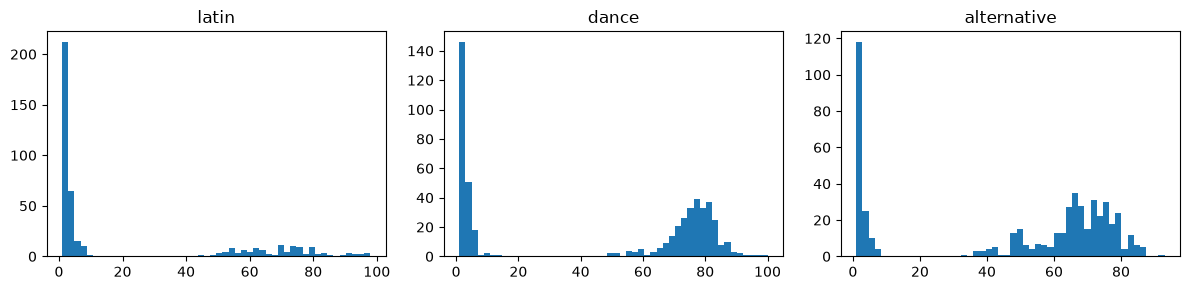

In [26]:
low = (d.assign(low=d["popularity"] <= 5)
        .groupby("track_genre").agg(low_share=("low", "mean"), n=("low", "size")))
print(low.sort_values("low_share", ascending=False).head(10).round(2))
print("Share of non-zero rows with popularity 1-5:", round((d["popularity"] <= 5).mean(), 3))
print(d["popularity"].value_counts().sort_index().head(8))

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, g in zip(axes, ["latin", "dance", "alternative"]):
    ax.hist(d.loc[d["track_genre"] == g, "popularity"], bins=50)
    ax.set_title(g)
plt.tight_layout()
plt.savefig("../images/popularity_hist_selected_genres.png", dpi=150, bbox_inches="tight")
plt.show()

Sensitivity analysis across three thresholds

In [27]:
def run_variant(label, threshold):
    sub = tracks[tracks["popularity"] > threshold].reset_index(drop=True).copy()
    sub["explicit"] = sub["explicit"].astype(int)
    Xa = sub[num_cols + ["explicit", "mode", "key", "time_signature"]]
    mlb = MultiLabelBinarizer()
    Gs = pd.DataFrame(mlb.fit_transform(sub["genres"]),
                      columns=[f"g{i}" for i in range(len(mlb.classes_))], index=sub.index)
    ys = sub["popularity"]
    sets = {
        "Audio only": (Xa, Pipeline([("prep", audio_prep), ("m", lgbm())])),
        "Genre only": (Gs, lgbm()),
        "Audio + genre": (pd.concat([Xa, Gs], axis=1),
                          Pipeline([("prep", audio_prep), ("m", lgbm())])),
    }
    rows = []
    for fname, (Xs, model) in sets.items():
        r = cv_eval(model, Xs, ys, sub["first_artist"])
        rows.append({"subset": label, "tracks": len(sub), "features": fname,
                     "R2": f"{r['R2'].mean():.3f} ± {r['R2'].std():.3f}",
                     "MAE": f"{r['MAE'].mean():.2f}",
                     "Spearman": f"{r['Spearman'].mean():.3f}"})
    return pd.DataFrame(rows)

sens = pd.concat([run_variant("all tracks (incl. 0)", -1),
                  run_variant("popularity > 0 (main)", 0),
                  run_variant("popularity > 5 (strict)", 5)], ignore_index=True)
print(sens.to_string(index=False))
sens.to_csv("../results/sensitivity_thresholds.csv", index=False)

                 subset  tracks      features            R2   MAE Spearman
   all tracks (incl. 0)   89740    Audio only 0.109 ± 0.016 15.53    0.332
   all tracks (incl. 0)   89740    Genre only 0.343 ± 0.011 11.80    0.604
   all tracks (incl. 0)   89740 Audio + genre 0.358 ± 0.013 11.72    0.618
  popularity > 0 (main)   80393    Audio only 0.165 ± 0.018 13.24    0.407
  popularity > 0 (main)   80393    Genre only 0.435 ± 0.016  9.77    0.678
  popularity > 0 (main)   80393 Audio + genre 0.457 ± 0.019  9.56    0.698
popularity > 5 (strict)   77690    Audio only 0.206 ± 0.021 12.46    0.447
popularity > 5 (strict)   77690    Genre only 0.564 ± 0.019  8.61    0.747
popularity > 5 (strict)   77690 Audio + genre 0.586 ± 0.018  8.40    0.764


Final checks and the explanation of the model

In [28]:
import shap
from sklearn.metrics import r2_score

# ---- Cell A: paired comparison of genre-only vs audio + genre, fold by fold
XG = pd.concat([X, G], axis=1)
diffs = []
for tr, te in GroupKFold(n_splits=5).split(XG, y, nz["first_artist"]):
    m_genre = lgbm().fit(G.iloc[tr], y.iloc[tr])
    m_both = Pipeline([("prep", audio_prep), ("m", lgbm())]).fit(XG.iloc[tr], y.iloc[tr])
    r_genre = r2_score(y.iloc[te], m_genre.predict(G.iloc[te]))
    r_both = r2_score(y.iloc[te], m_both.predict(XG.iloc[te]))
    diffs.append({"R2 genre only": r_genre, "R2 audio+genre": r_both,
                  "gain from audio": r_both - r_genre})
diffs = pd.DataFrame(diffs)
print(diffs.round(3))
print("Mean gain:", round(diffs["gain from audio"].mean(), 3),
      "| positive in", int((diffs["gain from audio"] > 0).sum()), "of", len(diffs), "folds")
diffs.to_csv("../results/audio_gain_per_fold.csv", index=False)

   R2 genre only  R2 audio+genre  gain from audio
0          0.449           0.463            0.014
1          0.454           0.484            0.030
2          0.425           0.451            0.026
3          0.416           0.432            0.016
4          0.431           0.453            0.023
Mean gain: 0.022 | positive in 5 of 5 folds


instrumentalness         1.15
energy                   0.88
duration_min             0.69
loudness                 0.69
genre: detroit-techno    0.56
valence                  0.53
genre: chicago-house     0.50
acousticness             0.49
genre: kids              0.48
genre: honky-tonk        0.48
danceability             0.46
genre: idm               0.41
speechiness              0.39
genre: grindcore         0.38
liveness                 0.38
dtype: float64
Average net contribution (popularity points): genre 8.11 | audio and other 2.76


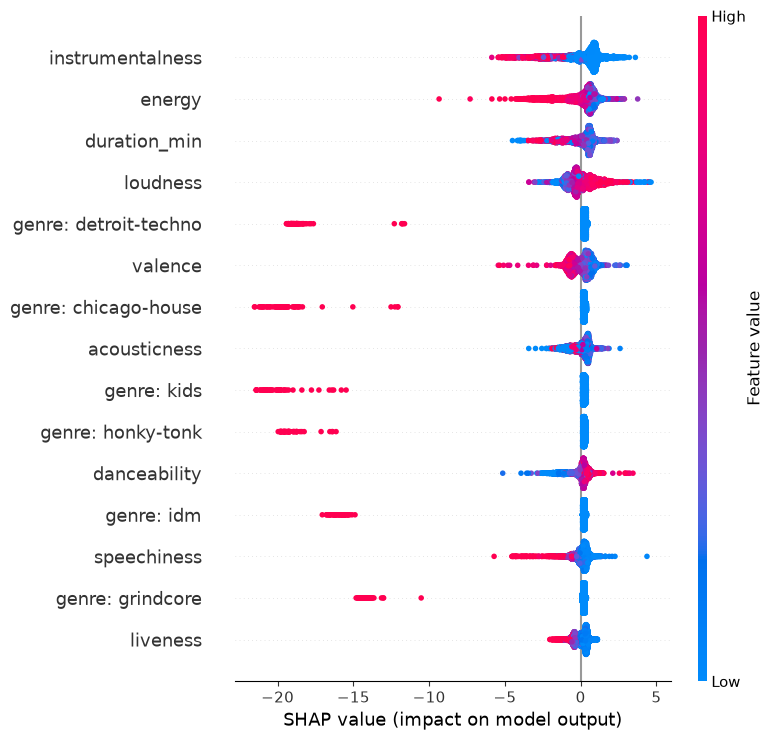

In [29]:
# ---- Cell B: explain the audio + genre model
pipe = Pipeline([("prep", audio_prep), ("m", lgbm())]).fit(XG, y)
sample = XG.sample(5000, random_state=0)
Xt = pipe.named_steps["prep"].transform(sample)
Xt = Xt.toarray() if hasattr(Xt, "toarray") else Xt
raw_names = pipe.named_steps["prep"].get_feature_names_out()

def pretty(nm):
    if nm.startswith("remainder__g"):
        return "genre: " + genre_names[int(nm.replace("remainder__g", ""))]
    return nm.split("__", 1)[1]

names = [pretty(nm) for nm in raw_names]
is_genre = np.array([nm.startswith("remainder__g") for nm in raw_names])

sv = shap.TreeExplainer(pipe.named_steps["m"]).shap_values(Xt)
imp = pd.Series(np.abs(sv).mean(0), index=names).sort_values(ascending=False)
print(imp.head(15).round(2))
imp.to_csv("../results/shap_importance.csv")

net_genre = np.abs(sv[:, is_genre].sum(1)).mean()
net_audio = np.abs(sv[:, ~is_genre].sum(1)).mean()
print(f"Average net contribution (popularity points): genre {net_genre:.2f} | audio and other {net_audio:.2f}")

plt.figure()
shap.summary_plot(sv, Xt, feature_names=names, max_display=15, show=False)
plt.savefig("../images/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

Save the app data

In [30]:
from pathlib import Path

slim_cols = ["track_id", "track_genre", "popularity", "danceability", "energy", "loudness",
             "speechiness", "acousticness", "instrumentalness", "liveness", "valence",
             "tempo", "duration_ms", "explicit"]
slim = df[slim_cols].copy()
float_cols = slim.select_dtypes("float").columns
slim[float_cols] = slim[float_cols].round(4)

Path("../app_data").mkdir(exist_ok=True)
slim.to_parquet("../app_data/tracks_genre_rows.parquet", compression="zstd", index=False)
print(round(Path("../app_data/tracks_genre_rows.parquet").stat().st_size / 1e6, 1), "MB")

4.2 MB


In [31]:
import subprocess, sys
from pathlib import Path

out = subprocess.run([sys.executable, "-m", "pip", "list", "--format=freeze"],
                     capture_output=True, text=True).stdout
wanted = {"pandas", "numpy", "scikit-learn", "lightgbm", "shap", "matplotlib",
          "scipy", "streamlit", "datasets", "pyarrow"}
lines, found = [], set()
for l in out.splitlines():
    name, _, ver = l.partition("==")
    if name.lower() in wanted:
        lines.append(f"{name}=={ver.split('+')[0]}")
        found.add(name.lower())
Path("../requirements.txt").write_text("\n".join(lines) + "\n")
print("\n".join(lines))
print("Missing:", sorted(wanted - found))

datasets==5.1.0
lightgbm==4.7.0
matplotlib==3.11.2
numpy==2.5.3
pandas==3.0.6
pyarrow==25.0.1
scikit-learn==1.9.1
scipy==1.18.1
shap==0.52.0
streamlit==1.65.0
Missing: []
